# Attention Mechanism on IMDB Movie Reviews
**JOTHIKA K (2114254050008/2025PECMECSE108)**

**Goal:** Classify reviews as positive/negative, and *show which words the model paid attention to*.


## Step 1: Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
FOLDER = '/content/drive/MyDrive/attention_project/'
print(os.listdir(FOLDER))   # you should see your two csv files

Mounted at /content/drive
['train_data.csv', 'test_data.csv']


## Step 2: Load and clean the data

In [2]:
import pandas as pd, numpy as np

# change these names if your files are named differently
TRAIN_FILE = 'train_data.csv'
TEST_FILE  = 'test_data.csv'

train = pd.read_csv(FOLDER + TRAIN_FILE, header=0, names=['text', 'label'])
test  = pd.read_csv(FOLDER + TEST_FILE,  header=0, names=['text', 'label'])

# remove html tags like <br /> and make lowercase
for df in (train, test):
    df['text'] = df['text'].str.replace(r'<.*?>', ' ', regex=True).str.lower()

print(train.shape, test.shape)
print(train['label'].value_counts())
train.head()

(25000, 2) (25000, 2)
label
0    12500
1    12500
Name: count, dtype: int64


,text,label
0,"this film is absolutely awful, but nevertheles...",0
1,well since seeing part's 1 through 3 i can hon...,0
2,i got to see this film at a preview and was da...,1
3,this adaptation positively butchers a classic ...,0
4,råzone is an awful movie! it is so simple. it ...,0


## Step 3: Convert words to numbers
Computers can't read words, so each word gets a number.

In [3]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_WORDS = 10000   # vocabulary size
MAX_LEN   = 200     # words kept per review

tok = Tokenizer(num_words=MAX_WORDS, oov_token='<unk>')
tok.fit_on_texts(train['text'])

X_train = pad_sequences(tok.texts_to_sequences(train['text']), maxlen=MAX_LEN)
X_test  = pad_sequences(tok.texts_to_sequences(test['text']),  maxlen=MAX_LEN)
y_train, y_test = train['label'].values, test['label'].values

print(X_train.shape, X_test.shape)

(25000, 200) (25000, 200)


## Step 4: Build the model with Attention
The attention layer does 3 simple things:
1. **Score** every word (how important is it?)
2. **Softmax** turns scores into percentages (total = 100%)
3. **Weighted sum** builds a summary mostly from important words

In [4]:
from tensorflow.keras import layers, Model

class Attention(layers.Layer):
    def build(self, input_shape):
        self.W = self.add_weight(shape=(input_shape[-1], 1),
                                 initializer='glorot_uniform', name='att_w')
    def call(self, x):
        scores  = tf.matmul(x, self.W)                 # 1. score every word
        weights = tf.nn.softmax(scores, axis=1)        # 2. scores -> percentages
        context = tf.reduce_sum(x * weights, axis=1)   # 3. weighted summary
        return context, tf.squeeze(weights, -1)

inp = layers.Input(shape=(MAX_LEN,))
x   = layers.Embedding(MAX_WORDS, 64)(inp)                              # words -> vectors
x   = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)   # understand context
context, att_weights = Attention()(x)                                   # focus on key words
out = layers.Dense(1, activation='sigmoid')(context)                    # positive / negative

model = Model(inp, out)
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 200, 128)       │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ attention (Attention)           │ [(None, 128), (None,   │           128 │
│                                 │ 200)]                  │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 706,305 (2.69 MB)

 Trainable params: 706,305 (2.69 MB)

 Non-trainable params: 0 (0.00 B)

## Step 5: Train the model (about 2-4 minutes on GPU)

In [5]:
history = model.fit(X_train, y_train,
                    validation_split=0.1,
                    epochs=4, batch_size=128)

Epoch 1/4
176/176 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.7804 - loss: 0.4419 - val_accuracy: 0.8544 - val_loss: 0.3270
Epoch 2/4
176/176 ━━━━━━━━━━━━━━━━━━━━ 4s 23ms/step - accuracy: 0.9046 - loss: 0.2388 - val_accuracy: 0.8772 - val_loss: 0.2917
Epoch 3/4
176/176 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.9319 - loss: 0.1808 - val_accuracy: 0.8648 - val_loss: 0.3153
Epoch 4/4
176/176 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9500 - loss: 0.1392 - val_accuracy: 0.8604 - val_loss: 0.3417


## Step 6: Test accuracy and training graph

Test accuracy: 86.10%


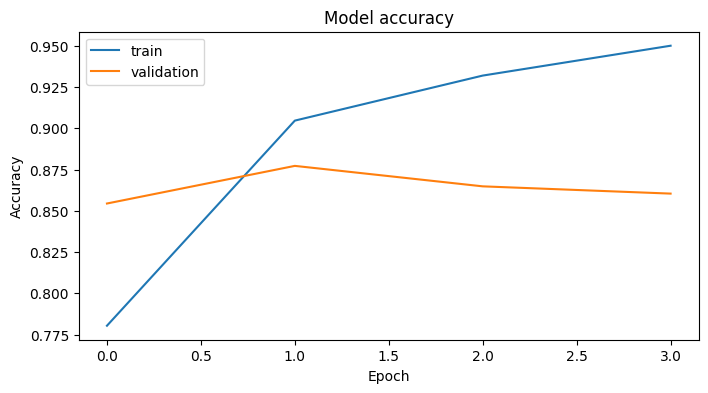

In [6]:
import matplotlib.pyplot as plt

loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {acc:.2%}")

plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title('Model accuracy'); plt.xlabel('Epoch'); plt.ylabel('Accuracy')
plt.legend(); plt.show()

## Step 7: See the attention (the demo for your mam!)

Prediction: POSITIVE (score = 0.70)


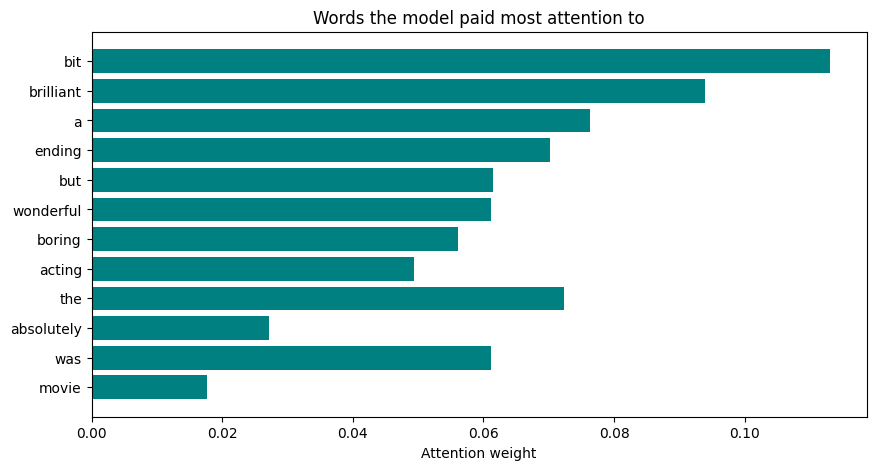

In [7]:
viewer = Model(inp, [out, att_weights])   # same model, but also returns attention

def show_attention(review_text, top_n=15):
    seq = pad_sequences(tok.texts_to_sequences([review_text.lower()]), maxlen=MAX_LEN)
    pred, w = viewer.predict(seq, verbose=0)
    words = [tok.index_word.get(i, '') for i in seq[0] if i != 0]
    w = np.array(w[0])[-len(words):]          # keep only real words (not padding)

    label = "POSITIVE" if pred[0][0] > 0.5 else "NEGATIVE"
    print(f"Prediction: {label} (score = {pred[0][0]:.2f})")

    top = np.argsort(w)[-top_n:]
    plt.figure(figsize=(10, 5))
    plt.barh([words[i] for i in top], w[top], color='teal')
    plt.title('Words the model paid most attention to')
    plt.xlabel('Attention weight')
    plt.show()

show_attention("This movie was absolutely wonderful, the acting was brilliant but the ending was a bit boring")

Actual label: NEGATIVE
Prediction: NEGATIVE (score = 0.01)


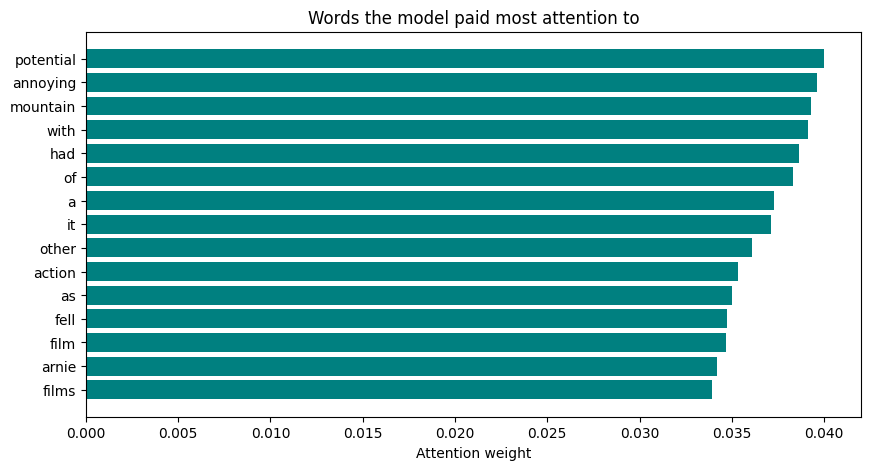

In [8]:
# try a real review from the test data
i = 0
print("Actual label:", "POSITIVE" if y_test[i] == 1 else "NEGATIVE")
show_attention(test['text'][i])

Prediction: NEGATIVE (score = 0.01)


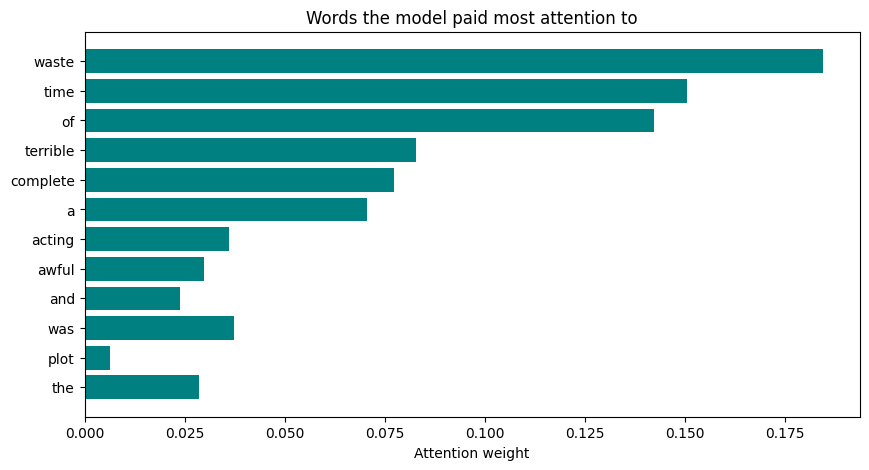

In [9]:
# try your own sentence!
show_attention("The plot was awful and the acting was terrible, a complete waste of time")

Prediction: POSITIVE (score = 0.92)


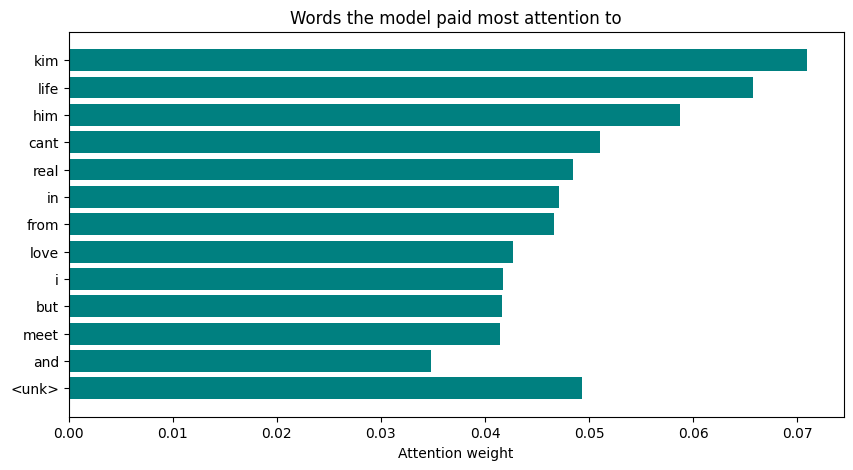

In [10]:
show_attention("My name is Jothika, I really am into kpop and kdrama.... i love KIM MINGYU from seventeen but i cant meet him in real life.")